In [69]:
import xarray as xr
import numpy as np
import pdb

In [72]:
path = '/nfs/scistore16/mullegrp/acasalla/MPI-C/Emissions/'

ds_AWB = xr.open_dataset(f'{path}/Subtractions/PM2.5/Agriculture/PM2.5_Agriculture_subtracted_from_TOTALS.nc')
ds_tot = xr.open_dataset(f'{path}TOTALS/PM2.5/PM2.5_TOTALS.nc')

<xarray.DataArray 'emissions' ()>
array(0.80248344, dtype=float32)


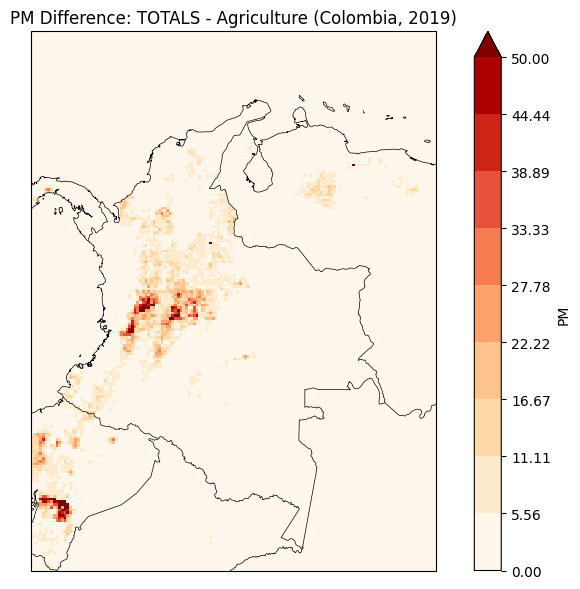

In [79]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define extent for Colombia
lat_min, lat_max = -5.0, 15.0
lon_min, lon_max = -80.0, -65.0

# Subset the difference to Colombia
#diff =  (ds_tot.emissions*1000/(365*86400) - ds_AWB.emissions*1000/(365*86400))
diff =  (ds_tot.emissions - ds_AWB.emissions)

print(diff.mean())
diff_colombia = diff.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

# Plot with Cartopy
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# Plot emission difference
#levels = np.linspace(0, 0.00050, 10)
#levels = np.linspace(0, 0.040050, 10)
levels = np.linspace(0, 50, 10)
diff_colombia.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='OrRd',
    levels=levels,
    cbar_kwargs={"label": "PM"},
)

# Add features
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
#ax.add_feature(cfeature.LAND, facecolor="none", edgecolor="black")
#ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
#ax.add_feature(cfeature.LAKES, facecolor="lightblue")
#ax.add_feature(cfeature.RIVERS, edgecolor="blue", linewidth=0.2)

# Title and labels
ax.set_title("PM Difference: TOTALS - Agriculture (Colombia, 2019)")
plt.show()


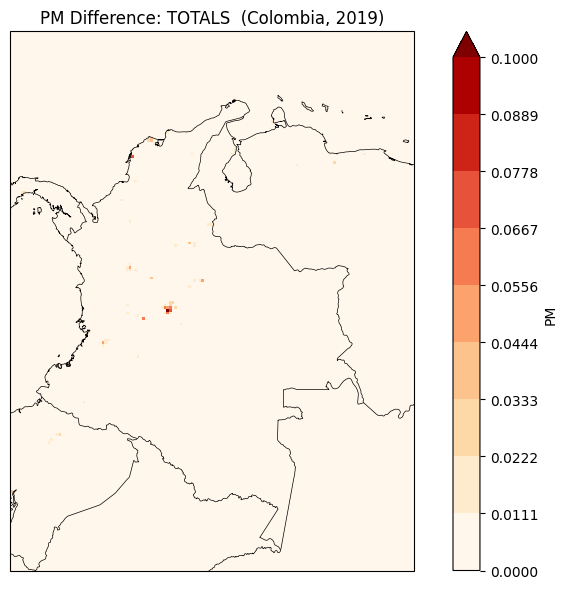

In [41]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Define extent for Colombia
lat_min, lat_max = -5.0, 15.0
lon_min, lon_max = -80.0, -65.0

# Subset the difference to Colombia
diff = ds_tot.emissions *1000/(365*86400)
diff_colombia = diff.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

# Plot with Cartopy
fig = plt.figure(figsize=(10, 7))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# Plot emission difference
levels = np.linspace(0, 0.1, 10)
diff_colombia.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap='OrRd',
    levels=levels,
    cbar_kwargs={"label": "PM"},
)

# Add features
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
#ax.add_feature(cfeature.LAND, facecolor="none", edgecolor="black")
#ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
#ax.add_feature(cfeature.LAKES, facecolor="lightblue")
#ax.add_feature(cfeature.RIVERS, edgecolor="blue", linewidth=0.2)

# Title and labels
ax.set_title("PM Difference: TOTALS  (Colombia, 2019)")
plt.show()


In [ ]:
Group Name	Included Sectors
Agriculture	AGS, AWB, ENF, MNM
Industry	IND, CHE, IRO, NFE, PRU_SOL
Energy_Use	ENE, REF_TRF, RCO
Fuel_Exploitation	PRO_COAL, PRO_GAS, PRO_OIL, FFF
Waste	SWD_INC, SWD_LDF, WWT
Road_Transport	TRO
Aviation	TNR_Aviation_CDS, TNR_Aviation_CRS, TNR_Aviation_LTO
Shipping	TNR_Ship
Off_Road_Transport	TNR_Other
Indirect_Emissions	IDE, N2O